# ARTI 403 – Image Processing | Lab 6
## Frequency Domain: Sobel Filtering

**Student Name:** Abdullah Hejji Alnuwaysir  
**Student ID:** 2240005501  

**Objective:** Apply Sobel X and Sobel Y filters to the Cameraman image in the frequency domain and display the results.

## 1. Import libraries and load the Cameraman image
The image is converted to a floating-point grayscale array and resized to 256 × 256 for efficient FFT computation.

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


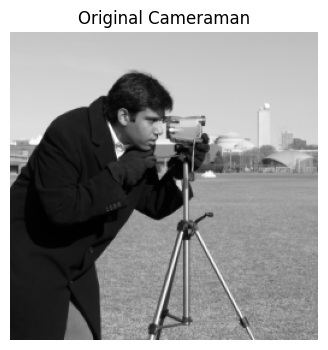

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

# Load the standard grayscale Cameraman image
image = data.camera()
image = resize(image, (256, 256), anti_aliasing=True)
image = np.asarray(image, dtype=float)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Original Cameraman")
plt.axis("off")
plt.show()

## 2. Define and center the Sobel kernels
The kernel is embedded in an image-sized zero array. `ifftshift` moves the kernel origin to the top-left before its FFT, so multiplication in the frequency domain corresponds to filtering.

In [2]:
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=float)

def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape, dtype=float)
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2
    padded[cy - kh//2:cy - kh//2 + kh,
           cx - kw//2:cx - kw//2 + kw] = kernel
    return np.fft.fft2(np.fft.ifftshift(padded))

## 3. Apply the filters in the frequency domain
Compute the 2D FFT of the image, multiply it by each Sobel filter's FFT, and use the inverse FFT to return to the spatial domain. The gradient magnitude combines both directions.

In [3]:
F = np.fft.fft2(image)

H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

G_x = np.fft.ifft2(F * H_x).real
G_y = np.fft.ifft2(F * H_y).real
gradient_magnitude = np.hypot(G_x, G_y)

print("Image shape:", image.shape)
print("Sobel X output shape:", G_x.shape)
print("Sobel Y output shape:", G_y.shape)
print("Gradient magnitude range:",
      float(gradient_magnitude.min()), "to",
      float(gradient_magnitude.max()))

Image shape: (256, 256)
Sobel X output shape: (256, 256)
Sobel Y output shape: (256, 256)
Gradient magnitude range: 0.0001100164921311417 to 3.4480914640183653


## 4. Display results

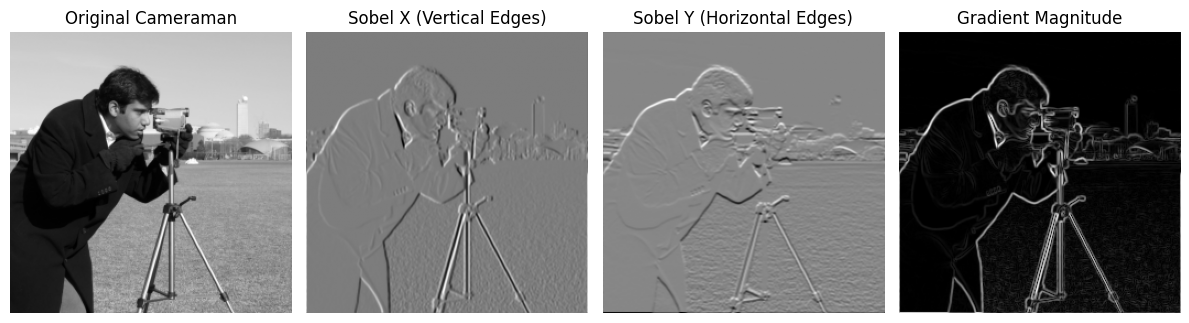

In [4]:
plt.figure(figsize=(12, 4))
outputs = [
    (image, "Original Cameraman"),
    (G_x, "Sobel X (Vertical Edges)"),
    (G_y, "Sobel Y (Horizontal Edges)"),
    (gradient_magnitude, "Gradient Magnitude")
]
for i, (result, title) in enumerate(outputs, 1):
    plt.subplot(1, 4, i)
    plt.imshow(result, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Results and observation

- **Sobel X** measures intensity changes along the horizontal direction and emphasizes **vertical edges**.
- **Sobel Y** measures intensity changes along the vertical direction and emphasizes **horizontal edges**.
- **Gradient magnitude** combines both responses, making edges in either direction visible.
- Filtering is performed by multiplying the image FFT by the corresponding filter FFT, followed by the inverse FFT.

**Conclusion:** The frequency-domain Sobel filters detect directional edges in the Cameraman image. The displayed outputs demonstrate the X-direction response, Y-direction response, and combined edge strength.